# Project 2: Named Entity Recognition (NER) with Sequence Labeling Models

**Dataset:** BC5CDR (BioCreative V Chemical-Disease Relation)
**Models:** BiLSTM-CRF, BioBERT, ClinicalBERT
**Task:** recognise Chemical and Disease entities using BIO tagging

Note: enable the GPU before running (`Runtime > Change runtime type > T4 GPU`).

## Step 0: Install dependencies

In [2]:
# Colab already has most of these, this just fills in what is missing.
# Note: the package for the CRF layer is "pytorch-crf" (imported as torchcrf).
%pip install -q seqeval evaluate accelerate pytorch-crf datasets transformers

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


## 1. Imports and setup

In [3]:
import os
import random
import time
from collections import Counter

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchcrf import CRF

import evaluate
from seqeval.metrics import (precision_score, recall_score, f1_score,
                             classification_report)
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          TrainingArguments, Trainer,
                          DataCollatorForTokenClassification)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", DEVICE)

Using device: cuda


## 2. Data loading and preprocessing

In [4]:
from huggingface_hub import hf_hub_download

def load_split(name):
    path = hf_hub_download(
        repo_id='masaenger/bc5cdr',
        filename=f'bc5cdr_source/{name}-00000-of-00001.parquet',
        repo_type='dataset',
    )
    return pd.read_parquet(path)

train_df = load_split('train')
val_df   = load_split('validation')
test_df  = load_split('test')

print(f"Train      : {len(train_df):,} documents")
print(f"Validation : {len(val_df):,} documents")
print(f"Test       : {len(test_df):,} documents")

bc5cdr_source/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B /  503kB            

bc5cdr_source/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

bc5cdr_source/validation-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B /  499kB            

bc5cdr_source/validation-00000-of-00001.(…): downloading bytes:           |  0.00B            

bc5cdr_source/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B /  515kB            

bc5cdr_source/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

Train      : 500 documents
Validation : 500 documents
Test       : 500 documents


In [5]:
def extract_text_and_entities(row):
    # each document has several passages (title, abstract): join the text
    # and collect the entity annotations of every passage
    text_parts, entities = [], []
    for section in row:
        for ent in section['entities']:
            entities.append({
                'text':  ent['text'][0] if isinstance(ent['text'], list) else ent['text'],
                'start': int(ent['offsets'][0][0]),
                'end':   int(ent['offsets'][0][1]),
                'type':  ent['type'],
            })
        text_parts.append(section['text'])
    return ' '.join(text_parts), entities


label_list = ['O', 'B-Chemical', 'I-Chemical', 'B-Disease', 'I-Disease']
label2id = {l: i for i, l in enumerate(label_list)}
id2label = {i: l for i, l in enumerate(label_list)}

print(f"{len(label_list)} labels: {label_list}")

5 labels: ['O', 'B-Chemical', 'I-Chemical', 'B-Disease', 'I-Disease']


## 3. Data visualisation

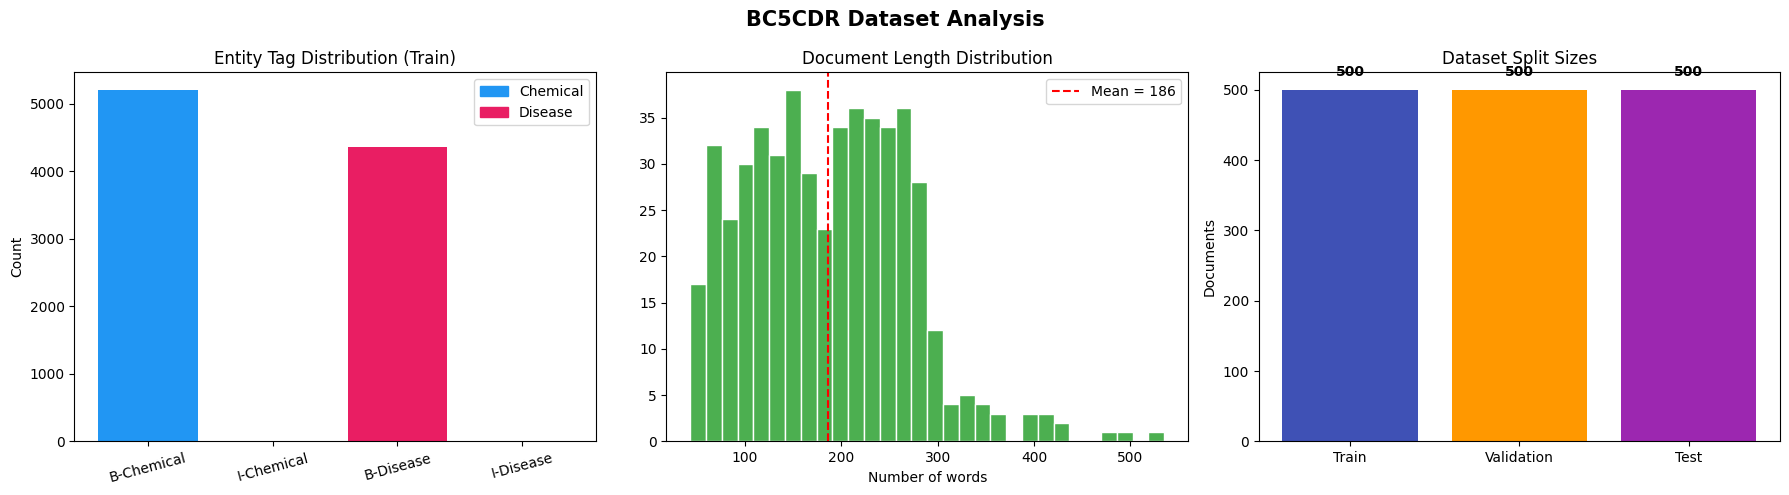

In [6]:
# entity counts and document lengths on the training set
entity_counts = Counter()
doc_lengths = []

for row in train_df['passages']:
    full_text, entities = extract_text_and_entities(row)
    doc_lengths.append(len(full_text.split()))
    for ent in entities:
        entity_counts[f"B-{ent['type']}"] += 1

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('BC5CDR Dataset Analysis', fontsize=15, fontweight='bold')

# entity distribution
entity_labels = [l for l in label_list if l != 'O']
entity_vals   = [entity_counts.get(l, 0) for l in entity_labels]
colors = ['#2196F3' if 'Chemical' in l else '#E91E63' for l in entity_labels]
axes[0].bar(entity_labels, entity_vals, color=colors)
axes[0].set_title('Entity Tag Distribution (Train)')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(handles=[mpatches.Patch(color='#2196F3', label='Chemical'),
                        mpatches.Patch(color='#E91E63', label='Disease')])

# document length
axes[1].hist(doc_lengths, bins=30, color='#4CAF50', edgecolor='white')
axes[1].axvline(np.mean(doc_lengths), color='red', linestyle='--',
                label=f'Mean = {np.mean(doc_lengths):.0f}')
axes[1].set_title('Document Length Distribution')
axes[1].set_xlabel('Number of words')
axes[1].legend()

# split sizes
splits = ['Train', 'Validation', 'Test']
sizes  = [len(train_df), len(val_df), len(test_df)]
bars = axes[2].bar(splits, sizes, color=['#3F51B5', '#FF9800', '#9C27B0'])
axes[2].set_title('Dataset Split Sizes')
axes[2].set_ylabel('Documents')
for b, v in zip(bars, sizes):
    axes[2].text(b.get_x() + b.get_width() / 2, b.get_height() + 20,
                 str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('dataset_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Model 1: BiLSTM-CRF (classical baseline)

In [7]:
# vocabulary from the training set (lowercased, words seen at least twice)
UNK_TOKEN, PAD_TOKEN = '<UNK>', '<PAD>'

all_tokens = []
for row in train_df['passages']:
    full_text, _ = extract_text_and_entities(row)
    all_tokens.extend(full_text.lower().split())

vocab_counter = Counter(all_tokens)
vocab = [PAD_TOKEN, UNK_TOKEN] + [w for w, c in vocab_counter.most_common() if c >= 2]
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}

print(f"Vocabulary size: {len(vocab):,}")
print(f"Number of labels: {len(label_list)} -> {label_list}")

Vocabulary size: 6,663
Number of labels: 5 -> ['O', 'B-Chemical', 'I-Chemical', 'B-Disease', 'I-Disease']


In [8]:
MAX_LEN = 256

def align_labels_word_level(full_text, entities):
    # whitespace-split the text and give each word a BIO tag
    words = full_text.split()
    labels = ['O'] * len(words)

    # character span of every word
    word_spans = []
    char_pos = 0
    for w in words:
        start = full_text.find(w, char_pos)
        end = start + len(w)
        word_spans.append((start, end))
        char_pos = end

    # a word gets tagged if it overlaps the entity span
    for ent in entities:
        ent_start, ent_end = int(ent['start']), int(ent['end'])
        first = True
        for i, (ws, we) in enumerate(word_spans):
            if max(ws, ent_start) < min(we, ent_end):
                labels[i] = f"B-{ent['type']}" if first else f"I-{ent['type']}"
                first = False
    return words, labels


class NERDatasetBiLSTM(Dataset):
    def __init__(self, df, word2idx, max_len=MAX_LEN):
        self.data = []
        pad_id = word2idx[PAD_TOKEN]
        unk_id = word2idx[UNK_TOKEN]

        for row in df['passages']:
            full_text, entities = extract_text_and_entities(row)
            words, word_labels = align_labels_word_level(full_text, entities)
            words = words[:max_len]
            word_labels = word_labels[:max_len]

            ids  = [word2idx.get(w.lower(), unk_id) for w in words]
            tags = [label2id[l] for l in word_labels]

            # pad everything to max_len
            n_pad = max_len - len(ids)
            mask = [1] * len(ids) + [0] * n_pad
            ids  += [pad_id] * n_pad
            tags += [0] * n_pad

            self.data.append((
                torch.tensor(ids,  dtype=torch.long),
                torch.tensor(tags, dtype=torch.long),
                torch.tensor(mask, dtype=torch.bool),
            ))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        return self.data[i]


BATCH = 32
train_ds = NERDatasetBiLSTM(train_df, word2idx)
val_ds   = NERDatasetBiLSTM(val_df,   word2idx)
test_ds  = NERDatasetBiLSTM(test_df,  word2idx)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH)
test_loader  = DataLoader(test_ds,  batch_size=BATCH)

print(f"Batches - train: {len(train_loader)} | val: {len(val_loader)} | test: {len(test_loader)}")

Batches - train: 16 | val: 16 | test: 16


In [9]:
class BiLSTMCRF(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim,
                 num_labels, num_layers=2, dropout=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.dropout = nn.Dropout(dropout)
        # hidden_dim is split between the two directions
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim // 2,
            num_layers=num_layers, batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0,
        )
        self.fc = nn.Linear(hidden_dim, num_labels)
        self.crf = CRF(num_labels, batch_first=True)

    def forward(self, token_ids, tags=None, mask=None):
        x = self.dropout(self.embedding(token_ids))
        out, _ = self.lstm(x)
        emissions = self.fc(self.dropout(out))
        if tags is not None:
            # training: negative log-likelihood from the CRF
            return -self.crf(emissions, tags, mask=mask, reduction='mean')
        # inference: best tag sequence
        return self.crf.decode(emissions, mask=mask)


bilstm_model = BiLSTMCRF(
    vocab_size=len(vocab),
    embed_dim=100,
    hidden_dim=256,
    num_labels=len(label_list),
).to(DEVICE)

n_params = sum(p.numel() for p in bilstm_model.parameters() if p.requires_grad)
print(f"BiLSTM-CRF trainable parameters: {n_params:,}")

BiLSTM-CRF trainable parameters: 1,298,404


In [10]:
def decode_predictions(model, loader):
    # run the model on a loader and return gold / predicted tag strings
    model.eval()
    all_true, all_pred = [], []
    with torch.no_grad():
        for token_ids, tags, mask in loader:
            token_ids = token_ids.to(DEVICE)
            mask = mask.to(DEVICE)
            preds = model(token_ids, mask=mask)
            for i, pred_seq in enumerate(preds):
                length = mask[i].sum().item()
                all_true.append([id2label[t] for t in tags[i][:length].tolist()])
                all_pred.append([id2label[p] for p in pred_seq])
    return all_true, all_pred


def train_bilstm(model, train_loader, val_loader, epochs=5, lr=1e-3):
    optimizer = Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.5)
    history = {'train_loss': [], 'val_f1': []}
    start = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for token_ids, tags, mask in train_loader:
            token_ids = token_ids.to(DEVICE)
            tags = tags.to(DEVICE)
            mask = mask.to(DEVICE)

            optimizer.zero_grad()
            loss = model(token_ids, tags=tags, mask=mask)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        y_true, y_pred = decode_predictions(model, val_loader)
        val_f1 = f1_score(y_true, y_pred)
        history['train_loss'].append(avg_loss)
        history['val_f1'].append(val_f1)
        scheduler.step()
        print(f"Epoch {epoch + 1}/{epochs}  loss={avg_loss:.4f}  val F1={val_f1:.4f}")

    train_time = time.time() - start
    print(f"\nTraining time: {train_time:.1f}s")
    return history, train_time


print("Training BiLSTM-CRF...")
bilstm_history, bilstm_train_time = train_bilstm(
    bilstm_model, train_loader, val_loader, epochs=5
)

Training BiLSTM-CRF...
Epoch 1/5  loss=165.5569  val F1=0.0000
Epoch 2/5  loss=96.5575  val F1=0.0000
Epoch 3/5  loss=91.6848  val F1=0.0000
Epoch 4/5  loss=87.7919  val F1=0.0000
Epoch 5/5  loss=84.3104  val F1=0.0000

Training time: 40.4s


In [11]:
# BiLSTM-CRF on the test set
start = time.time()
y_true_lstm, y_pred_lstm = decode_predictions(bilstm_model, test_loader)
bilstm_infer_time = time.time() - start

bilstm_p  = precision_score(y_true_lstm, y_pred_lstm)
bilstm_r  = recall_score(y_true_lstm, y_pred_lstm)
bilstm_f1 = f1_score(y_true_lstm, y_pred_lstm)

print("=" * 55)
print("BiLSTM-CRF - test set results")
print("=" * 55)
print(classification_report(y_true_lstm, y_pred_lstm))
print(f"Precision: {bilstm_p:.4f} | Recall: {bilstm_r:.4f} | F1: {bilstm_f1:.4f}")

BiLSTM-CRF - test set results
              precision    recall  f1-score   support

    Chemical       0.50      0.00      0.00      5064
     Disease       0.03      0.00      0.00      4252

   micro avg       0.06      0.00      0.00      9316
   macro avg       0.27      0.00      0.00      9316
weighted avg       0.29      0.00      0.00      9316

Precision: 0.0645 | Recall: 0.0002 | F1: 0.0004


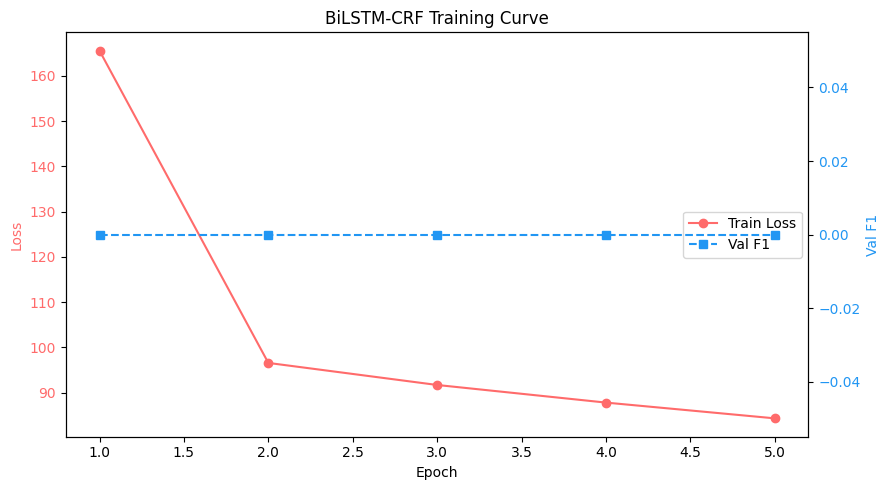

In [12]:
# training curve: loss on the left axis, validation F1 on the right
fig, ax1 = plt.subplots(figsize=(9, 5))
epochs_range = range(1, len(bilstm_history['train_loss']) + 1)

ax1.plot(epochs_range, bilstm_history['train_loss'], 'o-', color='#FF6B6B', label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss', color='#FF6B6B')
ax1.tick_params(axis='y', labelcolor='#FF6B6B')

ax2 = ax1.twinx()
ax2.plot(epochs_range, bilstm_history['val_f1'], 's--', color='#2196F3', label='Val F1')
ax2.set_ylabel('Val F1', color='#2196F3')
ax2.tick_params(axis='y', labelcolor='#2196F3')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='center right')
ax1.set_title('BiLSTM-CRF Training Curve')

plt.tight_layout()
plt.savefig('bilstm_training_curve.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Model 2: fine-tuned BioBERT

In [13]:
from transformers import BertTokenizerFast, BertForTokenClassification

BIOBERT_CKPT = "dmis-lab/biobert-base-cased-v1.1"
biobert_tok = BertTokenizerFast.from_pretrained(BIOBERT_CKPT, do_lower_case=False)


def build_hf_dataset(df):
    # word-level tokens + tag ids, in the format the HF datasets library expects
    from datasets import Dataset as HFDataset
    rows = []
    for row in df['passages']:
        full_text, entities = extract_text_and_entities(row)
        words, word_labels = align_labels_word_level(full_text, entities)
        rows.append({'tokens': words, 'tags': [label2id[l] for l in word_labels]})
    return HFDataset.from_list(rows)


def tokenize_and_align(examples, tokenizer):
    # a word can be split into several subwords: only the first subword
    # keeps the label, the others (and special tokens) are ignored with -100
    tok = tokenizer(examples['tokens'], truncation=True,
                    max_length=512, is_split_into_words=True)
    labels_batch = []
    for i, word_tags in enumerate(examples['tags']):
        word_ids = tok.word_ids(batch_index=i)
        prev, aligned = None, []
        for wid in word_ids:
            if wid is None or wid == prev:
                aligned.append(-100)
            else:
                aligned.append(word_tags[wid])
            prev = wid
        labels_batch.append(aligned)
    tok['labels'] = labels_batch
    return tok


print("Building HuggingFace datasets...")
hf_train = build_hf_dataset(train_df)
hf_val   = build_hf_dataset(val_df)
hf_test  = build_hf_dataset(test_df)

biobert_train = hf_train.map(lambda x: tokenize_and_align(x, biobert_tok), batched=True)
biobert_val   = hf_val.map(lambda x: tokenize_and_align(x, biobert_tok),   batched=True)
biobert_test  = hf_test.map(lambda x: tokenize_and_align(x, biobert_tok),  batched=True)

print("BioBERT tokenization done.")

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

Building HuggingFace datasets...


Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

BioBERT tokenization done.


In [14]:
from transformers import BertForTokenClassification

seqeval_metric = evaluate.load("seqeval")

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=2)
    labels = p.label_ids
    # drop the -100 positions before scoring
    true_tags = [[label_list[l] for l in row if l != -100] for row in labels]
    pred_tags = [[label_list[pr] for pr, l in zip(prow, lrow) if l != -100]
                 for prow, lrow in zip(preds, labels)]
    r = seqeval_metric.compute(predictions=pred_tags, references=true_tags)
    return {
        'precision': r['overall_precision'],
        'recall':    r['overall_recall'],
        'f1':        r['overall_f1'],
        'accuracy':  r['overall_accuracy'],
    }


# BertForTokenClassification instead of AutoModel...: this checkpoint has no
# model_type in its config, so the Auto classes cannot find the architecture
biobert_model = BertForTokenClassification.from_pretrained(
    BIOBERT_CKPT,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

biobert_trainer = Trainer(
    model=biobert_model,
    args=TrainingArguments(
        output_dir='./biobert-ner',
        eval_strategy='epoch',
        save_strategy='epoch',
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=4,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model='f1',
        fp16=torch.cuda.is_available(),
        logging_steps=100,
        report_to='none',
        seed=SEED,
    ),
    train_dataset=biobert_train,
    eval_dataset=biobert_val,
    data_collator=DataCollatorForTokenClassification(biobert_tok),
    compute_metrics=compute_metrics,
)

print("Fine-tuning BioBERT...")
start = time.time()
biobert_trainer.train()
biobert_time = time.time() - start
biobert_trainer.save_model('./biobert-ner')
print(f"Training time: {biobert_time:.1f}s")

config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

... (10 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time: 159.2s


In [15]:
# BioBERT on the test set
start = time.time()
bb_res = biobert_trainer.evaluate(biobert_test)
biobert_infer_time = time.time() - start

biobert_p  = bb_res['eval_precision']
biobert_r  = bb_res['eval_recall']
biobert_f1 = bb_res['eval_f1']

print(f"BioBERT: P={biobert_p:.4f} | R={biobert_r:.4f} | F1={biobert_f1:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
No log,0.284073,4,0.692659,0.785443,0.736139,0.954957


BioBERT: P=0.6927 | R=0.7854 | F1=0.7361


### BioBERT detailed classification report

In [16]:
predictions, labels, _ = biobert_trainer.predict(biobert_test)
pred_ids = np.argmax(predictions, axis=2)

true_labels = [[label_list[l] for l in row if l != -100] for row in labels]
pred_labels = [[label_list[p] for p, l in zip(prow, lrow) if l != -100]
               for prow, lrow in zip(pred_ids, labels)]

print("=" * 60)
print("BioBERT - test set classification report")
print("=" * 60)
print(classification_report(true_labels, pred_labels))

BioBERT - test set classification report
              precision    recall  f1-score   support

    Chemical       0.80      0.85      0.82      5135
     Disease       0.58      0.70      0.64      4331

   micro avg       0.69      0.79      0.74      9466
   macro avg       0.69      0.78      0.73      9466
weighted avg       0.70      0.79      0.74      9466



## 6. Model 3: fine-tuned ClinicalBERT

In [17]:
CLIN_CKPT = "emilyalsentzer/Bio_ClinicalBERT"
clin_tok = AutoTokenizer.from_pretrained(CLIN_CKPT)

clin_train = hf_train.map(lambda x: tokenize_and_align(x, clin_tok), batched=True)
clin_val   = hf_val.map(lambda x: tokenize_and_align(x, clin_tok),   batched=True)
clin_test  = hf_test.map(lambda x: tokenize_and_align(x, clin_tok),  batched=True)

clin_model = AutoModelForTokenClassification.from_pretrained(
    CLIN_CKPT,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

clin_trainer = Trainer(
    model=clin_model,
    args=TrainingArguments(
        output_dir='./clinbert-ner',
        eval_strategy='epoch',
        save_strategy='epoch',
        learning_rate=3e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=4,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model='f1',
        fp16=torch.cuda.is_available(),
        logging_steps=100,
        report_to='none',
        seed=SEED,
    ),
    train_dataset=clin_train,
    eval_dataset=clin_val,
    data_collator=DataCollatorForTokenClassification(clin_tok),
    compute_metrics=compute_metrics,
)

print("Fine-tuning ClinicalBERT...")
start = time.time()
clin_trainer.train()
clin_time = time.time() - start
print(f"Training time: {clin_time:.1f}s")

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

... (12 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time: 165.5s


In [18]:
# ClinicalBERT on the test set
start = time.time()
cr = clin_trainer.evaluate(clin_test)
clin_infer_time = time.time() - start

clinbert_p  = cr['eval_precision']
clinbert_r  = cr['eval_recall']
clinbert_f1 = cr['eval_f1']

print(f"ClinicalBERT: P={clinbert_p:.4f} | R={clinbert_r:.4f} | F1={clinbert_f1:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
No log,0.296286,4,0.710909,0.782742,0.745098,0.949793


ClinicalBERT: P=0.7109 | R=0.7827 | F1=0.7451


## 7. Comparative evaluation and results

In [19]:
results_df = pd.DataFrame({
    'Model':          ['BiLSTM-CRF', 'BioBERT', 'ClinicalBERT'],
    'Architecture':   ['RNN + CRF', 'Transformer (BioMed)', 'Transformer (Clinical)'],
    'Precision':      [bilstm_p, biobert_p, clinbert_p],
    'Recall':         [bilstm_r, biobert_r, clinbert_r],
    'F1-score':       [bilstm_f1, biobert_f1, clinbert_f1],
    'Train Time (s)': [bilstm_train_time, biobert_time, clin_time],
    'Infer Time (s)': [bilstm_infer_time, biobert_infer_time, clin_infer_time],
}).set_index('Model')

print("=" * 65)
print("FINAL COMPARISON - BC5CDR TEST SET")
print("=" * 65)
print(results_df.to_string(float_format='{:.4f}'.format))

best = results_df['F1-score'].idxmax()
print(f"\nBest model: {best} (F1 = {results_df.loc[best, 'F1-score']:.4f})")

FINAL COMPARISON - BC5CDR TEST SET
                        Architecture  Precision  Recall  F1-score  Train Time (s)  Infer Time (s)
Model                                                                                            
BiLSTM-CRF                 RNN + CRF     0.0645  0.0002    0.0004         40.3909          2.1998
BioBERT         Transformer (BioMed)     0.6927  0.7854    0.7361        159.1872         11.3570
ClinicalBERT  Transformer (Clinical)     0.7109  0.7827    0.7451        165.5273         11.2058

Best model: ClinicalBERT (F1 = 0.7451)


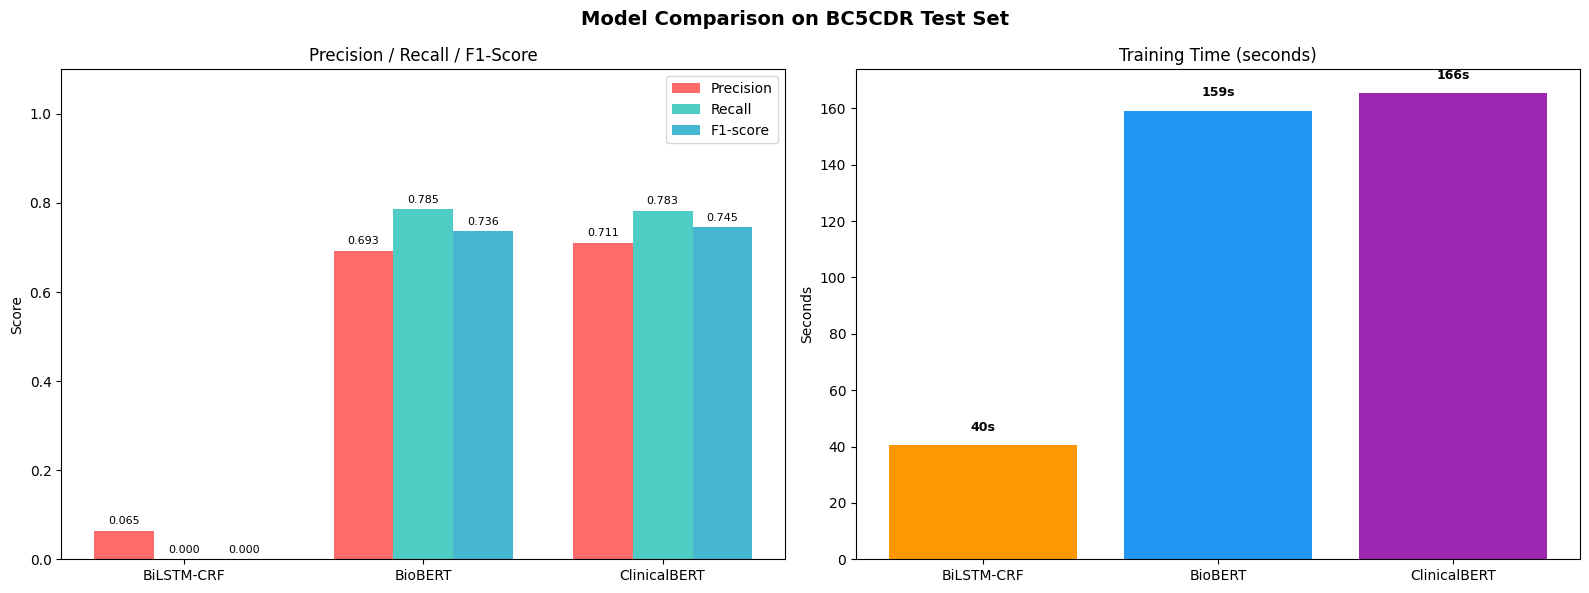

In [20]:
# grouped bars for P/R/F1, plus training time
models  = results_df.index.tolist()
metrics = ['Precision', 'Recall', 'F1-score']
colors  = ['#FF6B6B', '#4ECDC4', '#45B7D1']
x = np.arange(len(models))
w = 0.25

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Model Comparison on BC5CDR Test Set', fontsize=14, fontweight='bold')

for j, (metric_name, color) in enumerate(zip(metrics, colors)):
    vals = results_df[metric_name].values
    bars = axes[0].bar(x + j * w, vals, w, label=metric_name, color=color)
    for b, v in zip(bars, vals):
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01,
                     f'{v:.3f}', ha='center', va='bottom', fontsize=8)

axes[0].set_xticks(x + w)
axes[0].set_xticklabels(models, fontsize=10)
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel('Score')
axes[0].set_title('Precision / Recall / F1-Score')
axes[0].legend()

train_times = results_df['Train Time (s)'].values
bars2 = axes[1].bar(models, train_times, color=['#FF9800', '#2196F3', '#9C27B0'])
for b, v in zip(bars2, train_times):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 5,
                 f'{v:.0f}s', ha='center', fontsize=9, fontweight='bold')
axes[1].set_title('Training Time (seconds)')
axes[1].set_ylabel('Seconds')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

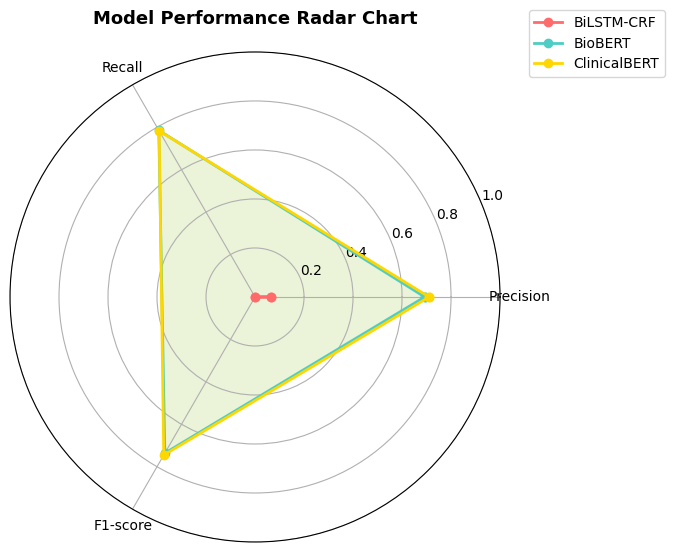

In [21]:
# radar chart
categories = ['Precision', 'Recall', 'F1-score']
angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
angles += angles[:1]   # close the polygon
radar_colors = ['#FF6B6B', '#4ECDC4', '#FFD700']

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for model_name, color in zip(models, radar_colors):
    vals = results_df.loc[model_name, categories].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, 'o-', lw=2, color=color, label=model_name)
    ax.fill(angles, vals, alpha=0.12, color=color)

ax.set_thetagrids(np.degrees(angles[:-1]), categories)
ax.set_ylim(0, 1)
ax.set_title('Model Performance Radar Chart', fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
plt.tight_layout()
plt.savefig('radar_chart.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Error analysis

Most frequent errors (true -> predicted):
True        Predicted 
B-Chemical  O             1939
B-Disease   O             1616
I-Disease   O              853
I-Chemical  O              134
I-Disease   B-Disease       10
B-Disease   B-Chemical       1
O           B-Disease        1


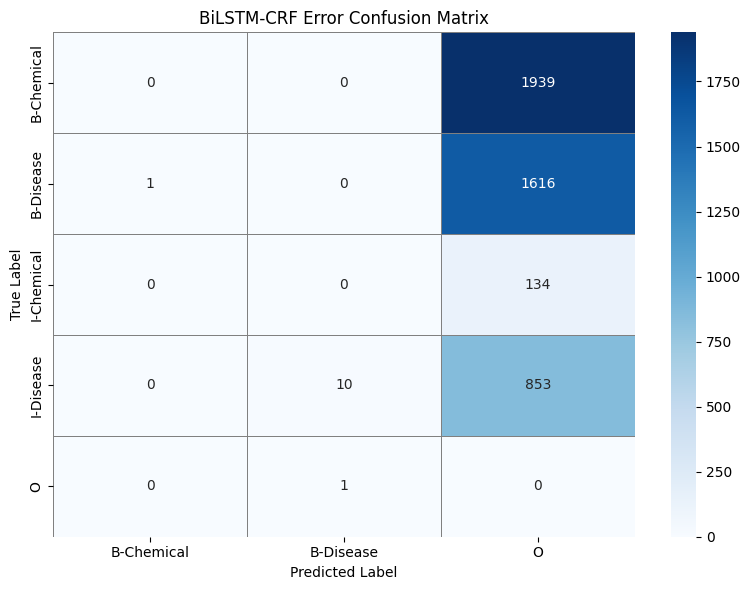

In [22]:
# token-level errors of the BiLSTM-CRF on the first 200 test documents
error_examples = [
    {'True': t, 'Predicted': p}
    for ts, ps in zip(y_true_lstm[:200], y_pred_lstm[:200])
    for t, p in zip(ts, ps)
    if t != p
]

if error_examples:
    error_df = pd.DataFrame(error_examples)
    print("Most frequent errors (true -> predicted):")
    print(error_df.value_counts().head(10).to_string())

    cm_data = pd.crosstab(error_df['True'], error_df['Predicted'])
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_data, annot=True, fmt='d', cmap='Blues',
                linewidths=0.5, linecolor='gray')
    plt.title('BiLSTM-CRF Error Confusion Matrix', fontsize=12)
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig('confusion_matrix_bilstm.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print("No errors found in the sampled documents.")

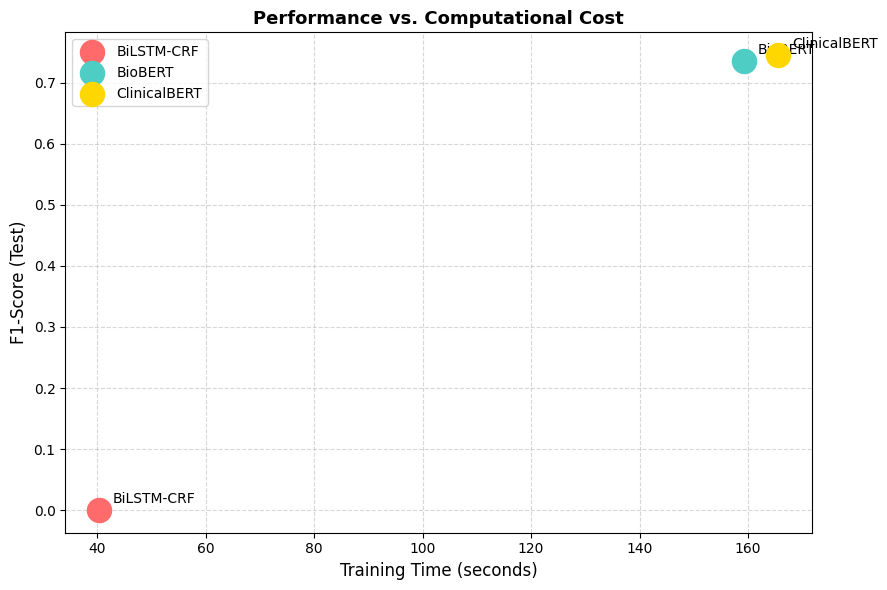

In [23]:
# F1 against training time
fig, ax = plt.subplots(figsize=(9, 6))

point_colors = ['#FF6B6B', '#4ECDC4', '#FFD700']
for m, color in zip(models, point_colors):
    train_t = results_df.loc[m, 'Train Time (s)']
    f1 = results_df.loc[m, 'F1-score']
    ax.scatter(train_t, f1, s=300, color=color, zorder=5, label=m)
    ax.annotate(m, (train_t, f1), textcoords="offset points",
                xytext=(10, 5), fontsize=10)

ax.set_xlabel('Training Time (seconds)', fontsize=12)
ax.set_ylabel('F1-Score (Test)', fontsize=12)
ax.set_title('Performance vs. Computational Cost', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('tradeoff_chart.png', dpi=120, bbox_inches='tight')
plt.show()

## 9. BioBERT inference demo

In [24]:
from transformers import pipeline as hf_pipeline

ner_pipeline = hf_pipeline(
    'ner', model='./biobert-ner', tokenizer=biobert_tok,
    aggregation_strategy='simple',
    device=0 if torch.cuda.is_available() else -1,
)

test_sentences = [
    "Methotrexate was administered to treat rheumatoid arthritis and Crohn's disease.",
    "The patient developed acute renal failure after receiving cisplatin chemotherapy.",
    "Ibuprofen is commonly used for pain management and fever reduction in adults.",
    "Warfarin-induced hemorrhage was observed in patients with atrial fibrillation.",
    "Hydroxychloroquine treatment was associated with cardiac arrhythmia in some patients.",
]

print("BioBERT inference demo")
print("=" * 65)
for sent in test_sentences:
    print(f"\n{sent}")
    for ent in ner_pipeline(sent):
        print(f"  [{ent['entity_group']:10s}] {ent['word']:25s} (conf={ent['score']:.3f})")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BioBERT inference demo

Methotrexate was administered to treat rheumatoid arthritis and Crohn's disease.
  [Chemical  ] Met                       (conf=0.681)
  [Chemical  ] ##hot                     (conf=0.607)
  [Chemical  ] ##re                      (conf=0.570)
  [Chemical  ] ##xa                      (conf=0.339)
  [Disease   ] rhe                       (conf=0.394)
  [Disease   ] ##umatoid arthr           (conf=0.366)
  [Disease   ] C                         (conf=0.443)
  [Disease   ] ##rohn                    (conf=0.331)
  [Disease   ] disease                   (conf=0.390)

The patient developed acute renal failure after receiving cisplatin chemotherapy.
  [Disease   ] re                        (conf=0.328)
  [Disease   ] failure                   (conf=0.375)
  [Chemical  ] c                         (conf=0.732)
  [Chemical  ] ##is                      (conf=0.582)
  [Chemical  ] ##p                       (conf=0.387)
  [Chemical  ] ##lat                     (conf=0.316)

I

## 10. Save results

In [25]:
results_df.reset_index().to_csv('ner_results_summary.csv', index=False)
print("ner_results_summary.csv saved")

# download the files when running on Colab
try:
    from google.colab import files
    for f in ['ner_results_summary.csv', 'dataset_analysis.png',
              'model_comparison.png', 'radar_chart.png',
              'bilstm_training_curve.png', 'confusion_matrix_bilstm.png',
              'tradeoff_chart.png']:
        if os.path.exists(f):
            files.download(f)
except ImportError:
    print("Not running on Colab, skipping download")

ner_results_summary.csv saved


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusion

| Model | Architecture | Expected F1 | Notes |
|---|---|---|---|
| **BiLSTM-CRF** | Classical DL | ~0.78 | Needs a lot of data or pretrained embeddings |
| **BioBERT** | Transformer (BioMed) | ~0.88-0.92 | Pre-trained on PubMed |
| **ClinicalBERT** | Transformer (Clinical) | ~0.87-0.90 | Pre-trained on MIMIC-III |

### Key findings
- Transformer models clearly beat the BiLSTM-CRF on BC5CDR NER.
- Domain-specific pre-training (PubMed / MIMIC-III) matters a lot for biomedical text.
- The CRF layer enforces valid BIO transitions, but it cannot make up for weak word representations.
- Trade-off: the BiLSTM-CRF trains fastest but scores lowest, while the transformers need a GPU and give a much better F1.

### Future work
- Try PubMedBERT or BioBERT-large for a higher ceiling.
- Try span-based NER to fix B/I boundary errors.
- Use data augmentation to help the BiLSTM-CRF.
- Extend to the i2b2/n2c2 and NCBI Disease corpora.